# assignment 1, additional report: improved motor model

###### *extends `robotics_lab5_240057.ipynb`*

setup: 
- 3 complex signals (square, sawtooth, triangle);
- both wheels lifted (motor M4 receives $u$ and motor M3 receives $-u$);
- each run has 3 s of rest, 8 s of execution, 1 s of coasting;

**summary:**

initial model $T_m\dot\omega+\omega=U/k_e$ is the special case $U_0=0,\ c=0$ of one equation derived from the dc-motor equations:
$$\tau\dot\omega=U-\operatorname{sgn}(\omega)\,(U_0+a|\omega|+c\,\omega^2)$$
its assumptions (no dead zone, linear drag, symmetry between fwd and bwd) were tested on the 3 complex signals: each signal alone is used for identification, the other two for testing. the step logs of the main report are used *only* as an unfitted check

- dead zone: with $U_0$ and $a$ separate per direction, dead-zone voltages $U_{fw}$, $U_{bw}$ come out at 0-0.06V (at most 0.6% PWM) for every signal and both wheels; adding $U_0$ alone does not beat the initial model (mean speed fit 58% vs 60%)
- asymmetry is small and depends on the signal:
    - identified on the triangle: the backward drag relative to forward is $b_{bw}=0.02$ (M4) and $-0.015$ (M3), as small as the slope differences in main report (4.9% and 1.6%);
    - identified on the sawtooth: $b_{bw}=-0.20$ (M4) and $-0.32$ (M3)
        - speed prediction improves a lot there (35% to 80% speed fit on the other two signals), but angle prediction gets worse (median angle fit $-57$% vs $-20$%)
- quadratic drag $c$, speed-dependent loss are helpful:
    - it is the best for every signal and both wheels, and gains only 1-2 points of speed fit on the test signals;
    - against step logs *(never fitted)* steady-speed error at 70-100% PWM drops from 5.2 / 6.6 rad/s (initial) and 4.9 / 6.6 (with $U_0$ and asymmetry) to 0.8 / 1.4 rad/s (M4 / M3, identified on the triangle); 
- final formula (in sect. 6):
    - $U_0$ + asymmetry + $c$ (constants from the triangle);
    - the forward/backward constants are uncertain (given that they change with the signal)
        - $c\approx0.03$ V s$^2$/rad$^2$ is supported by the step logs

## 1. derivation of improved model

<!-- derive the dc motor eq w friction -> write init model model as sp.case -> list what it assumes -> show improved model -->
notation: $p$ = commanded PWM [%], $U=pU_b/100$ applied voltage [V], $\omega$ wheel speed [rad/s], $\theta$ angle [rad]

- armature: $U=iR+K\omega$ (inductance neglected, $L=0$: the sample interval of 46-58 ms could not show $L/R$ anyway);
- torque $T_e=Ki$ (in SI units the back-emf constant equals the torque constant);
- eliminating $i$ gives $T_e=\dfrac{K}{R}(U-K\omega)$
- mechanics with friction:
$$J\dot\omega=T_e-T_c\operatorname{sgn}\omega-B_1\omega-B_2\,\omega|\omega|$$

where $T_c$ is dry friction, $B_1$ viscous (linear) drag and $B_2$ quadratic drag; 

substitute $T_e$, multiply by $R/K$ and collect the terms with $\omega$:

$$\frac{JR}{K}\dot\omega=U-\Bigl(K+\frac{RB_1}{K}\Bigr)\omega-\frac{RT_c}{K}\operatorname{sgn}\omega-\frac{RB_2}{K}\,\omega|\omega|$$

| formula | meaning | unit |
|---|---|---|
| $\tau=JR/K$ | inertia constant | V s$^2$/rad |
| $a=K+RB_1/K$ | back-emf + viscous drag ("apparent $k_e$") | V s/rad |
| $U_0=RT_c/K$ | voltage used up by dry friction | V |
| $c=RB_2/K$ | quadratic drag | V s$^2$/rad$^2$ |

$$\boxed{\;\tau\,\dot\omega \;=\; U-\operatorname{sgn}(\omega)\bigl(U_0+a|\omega|+c\,\omega^2\bigr),\qquad \dot\theta=\omega\;}$$
at rest the wheel stays at rest while $|U|\le U_0$ (sticking friction = dead zone), and friction can stop the wheel but never reverse it. 

only $\tau,U_0,a,c$ can be identified: six physical numbers ($R,K,J,B_1,B_2,T_c$) enter through these 4 combinations, since no current or torque was measured.

### 1.1 initial model as a special case
let $U_0=0$ and $c=0$: $\tau\dot\omega=U-a\omega$; 

divide by $a$:
$$\frac{\tau}{a}\,\dot\omega+\omega=\frac{U}{a}\qquad\Longrightarrow\qquad T_m=\frac{\tau}{a},\quad k_e=a$$
and we get $T_m\dot\omega+\omega=U/k_e$ used in main report, so our initial model assumes:

| assumption | reality |
|---|---|
| inductance negligible: $L=0$ | kept |
| no dry friction, no dead zone: $U_0=0$ | **tested** |
| drag linear in speed: $c=0$ | **tested** |
| voltage proportional to PWM: $U=pU_b/100$ | kept |
| forward = backward (one set of constants for both directions) | **tested** |

### 1.2 dead zone and different forward / backward constants

the same equation with $c=0$ and separate constants per direction is a system of equations ($\varepsilon$ is a small speed threshold):
$$\dot\omega=\begin{cases}-\dfrac{1+b_{fw}}{T_m}\,\omega+\dfrac{U-U_{fw}}{T_mk_e}, & \omega>\varepsilon\ \text{ or }\ (|\omega|\le\varepsilon,\ U>U_{fw}),\\[3mm]-\dfrac{1+b_{bw}}{T_m}\,\omega+\dfrac{U+U_{bw}}{T_mk_e}, & \omega<-\varepsilon\ \text{ or }\ (|\omega|\le\varepsilon,\ U<-U_{bw}),\\[3mm]0, & \text{otherwise (at rest, } -U_{bw}\le U\le U_{fw}\text{)}\end{cases}$$

- $U_{fw},U_{bw}$ are dead zone voltages
- $b_{fw},b_{bw}$ extra drag on top of the back-emf term

multiply by $T_mk_e$ and put $\tau=T_mk_e$:
$$\tau\dot\omega=U-U_d-k_e(1+b)\,\omega,\qquad U_d=U_{fw}\ \text{(forward)},\quad U_d=-U_{bw}\ \text{(backward)}$$

this is the equation with $c=0$ in each direction:
$$U_0^{fw}=U_{fw},\quad U_0^{bw}=U_{bw},\quad a_{fw}=k_e(1+b_{fw}),\quad a_{bw}=k_e(1+b_{bw}),\quad \tau=T_mk_e$$

- $U_{fw}=U_{bw}=0$ ^ $b=0$ give back the initial model;
- $U_{fw}\ne U_{bw}$ v $b_{fw}\ne b_{bw}$ is asymmetry;

what can be identified: 

given form has 6 constants, but equation contains only 5 numbers $(\tau,a_{fw},a_{bw},U_{fw},U_{bw})$: 

- the change $(T_m,k_e,b)\to(\lambda T_m,\,k_e/\lambda,\,\lambda(1+b)-1)$ leaves the motion unchanged:
    - so one constant $b_{fw}=0$ is fixed, then:
       $k_e=a_{fw}$, $T_m=\tau/a_{fw}$, and $b_{bw}=a_{bw}/a_{fw}-1$ is the backward drag relative to forward;
    - steady speed in each direction is $\omega_{ss}=(|U|-U_0)/a$, a line with slope $1/a$ (difference of 2 slopes is what was measured in main report - 4.9% for M4, 1.6% for M3);

### 1.3 one extra term, $c$
in main report it was found that:

- speed-voltage curve bends and that $T_m$ falls with speed (0.4-0.05s); with $c=0$ both stay constant;
- with $c>0$ the steady state is $U=U_0+a\omega+c\omega^2$, so $\omega_{ss}=\dfrac{-a+\sqrt{a^2+4c\,(U-U_0)}}{2c}$, a curve that bends down. for small changes around a speed $\omega_0$ the equation acts becomes a first order system with
$$T_m(\omega_0)=\frac{\tau}{a+2c\,\omega_0}$$
*so the faster the wheel turns, the faster it responds.* $c$ is not part of the system in section 1.2, so it is tested as the last version below.

### 1.4 versions that are fitted
versions are named by their free constants. $\tau$ is shared by both directions; "one" = same constant for both directions; "per dir." = separate:

| version | $U_0$ | $a$ | $c$ | constants per wheel | what it tests |
|---|---|---|---|---|---|
| initial | 0 | one | 0 | 2 | initial model, all assumptions kept |
| a per dir. | 0 | per dir. | 0 | 3 | asymmetry alone |
| U0 | one | one | 0 | 3 | dead zone alone |
| U0 + a per dir. | per dir. | per dir. | 0 | 5 | model in 1.2 (system of eq-s. |
| U0 + a per dir. + c | per dir. | per dir. | one | 6 | quadratic drag on top |

## 2. data

2 sets of recordings (angle and command of M3 are flipped to the robot-forward convention):

- set B (12 Nov, battery 10.89 V): square wave ($\pm60$%, 1s period), sawtooth (60%, 1s), triangle (60%, 4s period); each signal in turn is the identification signal, the other two are test signals
- set A (1 Nov, battery 11.19 V, from initial assign. 1): square and sawtooth, same settings; an extra external test (for $U=pU_b/100$)

*note: as of now triangle is the slowest signal available (possibly an extension with low freq chirp is gonna be made once data for that will be collected...)*

In [226]:
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from scipy.optimize import least_squares
from scipy.ndimage import uniform_filter1d
from IPython.display import display, Markdown, Image

DATA = Path('motor_data')
FIGURES = Path('figures'); 
FIGURES.mkdir(exist_ok=True)
MOTORS = {4: 'Left M4/E4', 3: 'Right M3/E3'}
DT = 0.01 # sim step (s)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES/f'improved3_{name}.png', dpi=140)
    plt.close(fig)
    display(Image(filename=str(FIGURES/f'improved3_{name}.png')))

# cols: angle_l_deg,time_ms,pwm_l,angle_r_deg,pwm_r,run,phase,segment,onset_ms,(battery_V)
def load(path, vb=None, run_offset=0):
    # case: 10 columns -> battery in the last one
    # case: 9 columns -> battery taken from a dict {run: volts} (in sep battery logfile
    d = np.loadtxt(path, delimiter=','); assert d.shape[1] in (9, 10)
    run = d[:, 5].astype(int)
    Vb = d[:, 9] if d.shape[1] == 10 else np.array([vb[r] for r in run])
    out = []
    for motor, ca, cp, sg in [(4, 0, 2, 1), (3, 3, 4, -1)]: # motor M3 is mirrored to robot fwd
        out.append(pd.DataFrame(dict(
            motor=motor, 
            theta=sg*np.deg2rad(d[:, ca]), 
            time=d[:, 1]/1000, 
            pwm=sg*d[:, cp],
            run=run+run_offset, 
            phase=d[:, 6].astype(int), 
            onset=d[:, 8]/1000, Vb=Vb
        )))
    return pd.concat(out, ignore_index=True)

bat = pd.read_csv(DATA/'battery_sigs_57.txt')
vb = bat.groupby('rep').voltage_V.mean().to_dict()

# run A: signal_240057.txt; runs 1 = square, 2 = sawtooth, 10 cols w battery
# run B: sigs_57.txt, runs 1 = square, 2 = sawtooth, 3 = triangle, 9 columns w battery in battery_sigs_57.txt.
# B run numbers are shifted by +10 in memory (11, 12, 13) so they do not collide with run A
sessB = load(DATA/'sigs_57.txt', vb=vb, run_offset=10)
sessA = load(DATA/'signal_240057.txt')
signal = pd.concat([sessB, sessA], ignore_index=True)
NAMES = {1: 'square (A)', 2: 'sawtooth (A)', 11: 'square', 12: 'sawtooth', 13: 'triangle'}
TRAIN = [11, 12, 13]
EXTERNAL = [1,2]
def sig(m, run): return signal[(signal.motor == m) & (signal.run == run)]

rows = []
for run in TRAIN + EXTERNAL:
    g = sig(4, run); ex = g[g.phase >= 3]
    rows.append({
        'run': NAMES[run], 
        'set': 'B' if run in TRAIN else 'A (external)',
        'duration of excitation (s)': ex.time.iloc[-1] - ex.time.iloc[0], 
        'PWM range (%)': f'{g.pwm.min():.0f} to {g.pwm.max():.0f}',
        'sample interval (ms)': 1000*np.diff(ex.time).mean(), 
        'battery (V)': g.Vb.mean()
    })
display(pd.DataFrame(rows).set_index('run').round(2))

,set,duration of excitation (s),PWM range (%),sample interval (ms),battery (V)
run,,,,,
square,B,7.98,-60 to 60,48.68,10.90
sawtooth,B,7.98,-60 to 60,57.81,10.88
triangle,B,7.99,-60 to 60,45.68,10.89
square (A),A (external),7.96,-60 to 60,47.69,11.19
sawtooth (A),A (external),7.98,-60 to 59,47.48,11.17


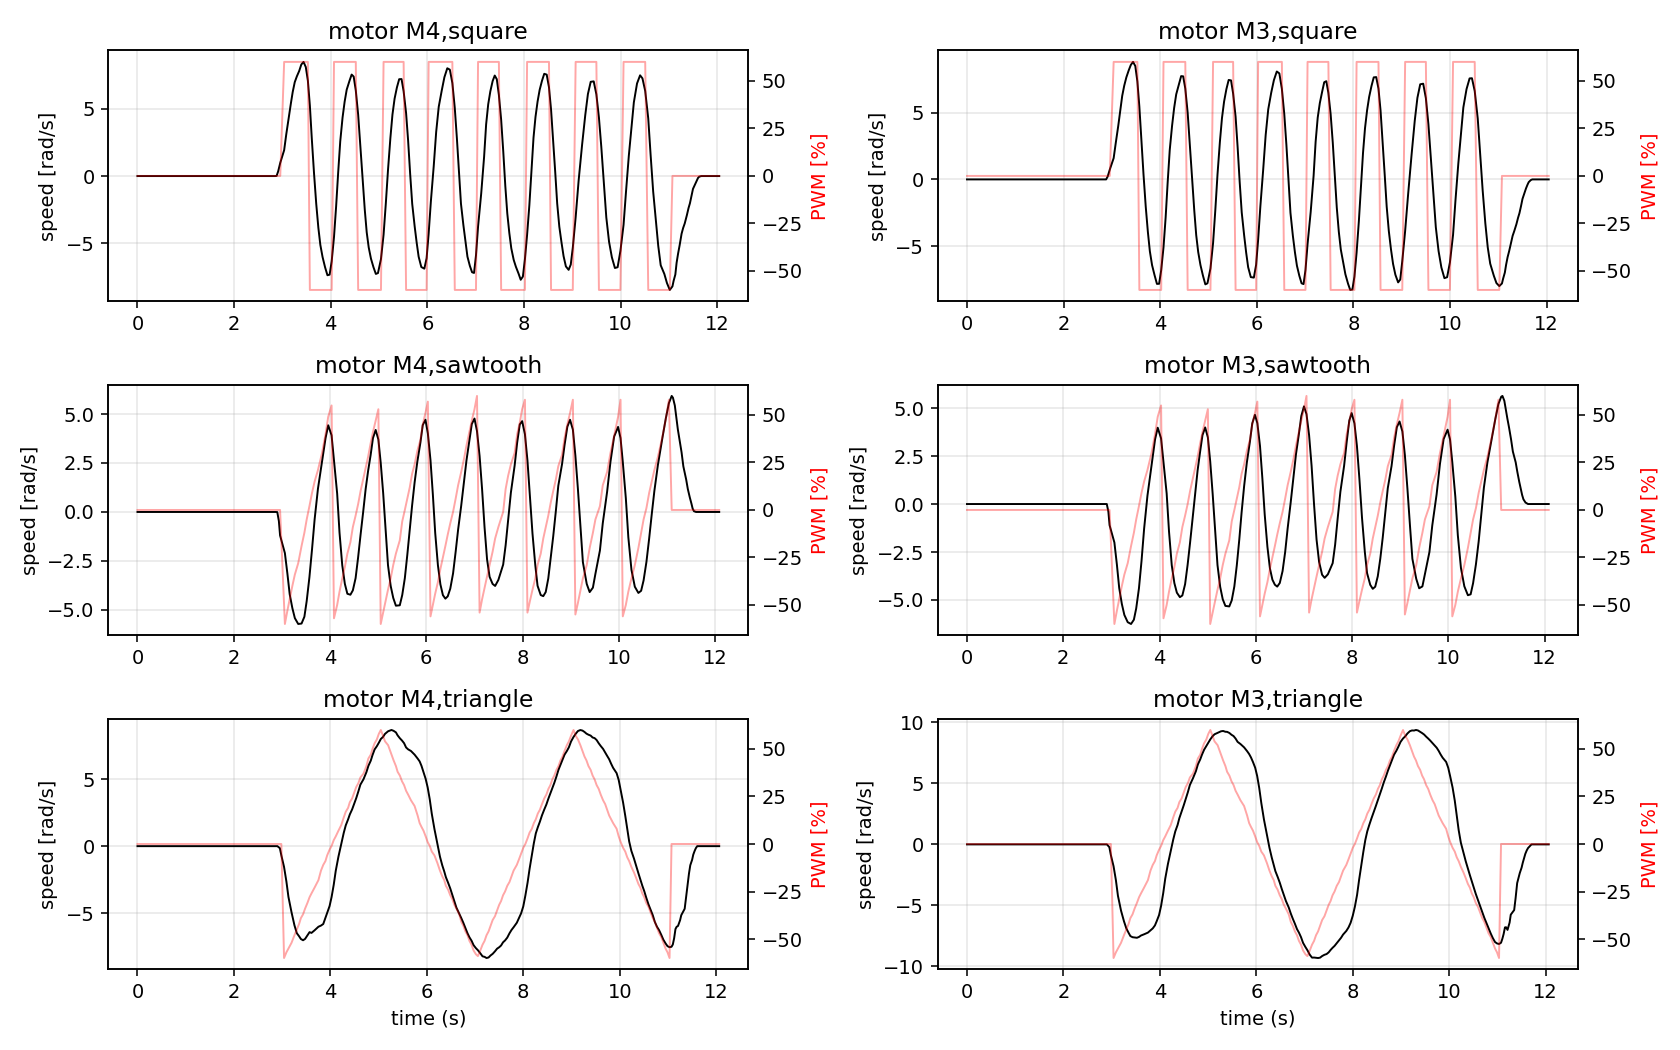

In [227]:
fig, axes = plt.subplots(3, 2, figsize=(12, 7.5), sharex='row')
for r_, run in enumerate(TRAIN):
    for c, m in enumerate(MOTORS):
        g = sig(m, run); 
        t = g.time.to_numpy()-g.time.iloc[0];
        y = (g.theta - g.theta.iloc[0]).to_numpy();
        w = uniform_filter1d(np.gradient(y, t), 5, mode='nearest'); 
        
        ax = axes[r_, c]
        ax.plot(t,w,'k',lw=1); 
        ax.set(ylabel='speed [rad/s]', title=f'motor M{m},{NAMES[run]}'); 
        ax.grid(alpha=.3)
        
        a2 = ax.twinx();
        a2.plot(t,g.pwm,'r',alpha=.35, lw=1); 
        a2.set_ylabel('PWM [%]', color='r')
        if r_ == 2: ax.set_xlabel('time (s)')
show(fig, 'fig1_signals')

fig. 1: 3 signals of set B: measured speed (black, 5-point mean of `np.gradient`) and PWM (red); all reach only $\pm60$% PWM, so predictions above 60% lie outside the fitted range

## 3. identification

equation is non-linear in its constants and $\omega$ is not measured, only angle in 1-degree steps every ~50 ms. regression on $\dot\omega$ (the RLS route of the dc-motor paper) would differentiate rounded signal twice, so simulation error is minimised instead: 
- simulate the equation with the recorded PWM
- compare with the measurement
- then let `scipy.optimize.least_squares` change the constants

simulation step $\Delta t=10$ ms, PWM held between log rows, $U_k=p_kU_b/100$, $s_k=\operatorname{sgn}(\omega_k)$ ($\operatorname{sgn}U_k$ at rest), constants of the current direction:
$$\omega_{k+1}=\omega_k+\frac{\Delta t}{\tau}\Bigl[U_k-s_k\bigl(U_0+a|\omega_k|+c\,\omega_k^2\bigr)\Bigr],\qquad \theta_{k+1}=\theta_k+\Delta t\,\omega_{k+1}$$
wheel stays at rest while $|U|\le U_0$, and friction cannot reverse it. for $c=0$ this is the model of section 1.2

the cost compares angle and speed at the $N$ samples of the identification signal (initial rest excluded), each divided by its standard deviation so that rad and rad/s weigh the same:
$$J(\vartheta)=\sum_{j=1}^{N}\Bigl[\Bigl(\frac{\theta^{sim}_j-\theta_j}{\sigma_\theta}\Bigr)^2+\Bigl(\frac{\bar\omega^{sim}_j-\bar\omega_j}{\sigma_\omega}\Bigr)^2\Bigr]$$
with $\bar\omega$ the 5-point mean (the same filter is applied to the simulated speed), ($U_0,c\ge0$, $a,\tau>0$) and constant on a bound is flagged. 

scores: $\mathrm{RMSE}$ and fit $=100\,(1-\lVert y-\hat y\rVert/\lVert y-\bar y\rVert)$ (100% perfect, negative = worse than the mean);

identification algorithm: for each of the 3 signals of set B, each wheel and each version, fit on that signal alone, then score on the other 2 signals of set B and on the 2 signals of set A

In [242]:
def prepare(g):
    t = g.time.to_numpy(); y = (g.theta - g.theta.iloc[0]).to_numpy(); mk = g.phase.to_numpy() != 0
    wm = uniform_filter1d(np.gradient(y, t), 5, mode='nearest')
    ch = g.pwm.ne(g.pwm.shift()).to_numpy(); 
    on, cmd = g.onset.to_numpy()[ch], g.pwm.to_numpy()[ch]; # PWM held between changes
    tg = np.arange(t[0], t[-1] + DT, DT)
    cmd_t = cmd[np.clip(np.searchsorted(on, tg, side='right') - 1, 0, None)]
    vb_t = g.Vb.to_numpy()[np.clip(np.searchsorted(t, tg, side='right') - 1, 0, None)]
    pos = (t - tg[0])/DT; 
    i0 = np.clip(np.floor(pos).astype(int), 0, len(tg)-2)
    return dict(t=t, y=y, mk=mk, wm=wm, 
                U=cmd_t*vb_t/100, i0=i0, 
                f=pos-i0, sy=y[mk].std(), 
                sw=wm[mk].std())

RUN = {(m, r): prepare(sig(m, r)) for m in MOTORS for r in TRAIN + EXTERNAL}

# param set per row of P: [tau, U0f, af, cf, U0b, ab, cb]  (f = forward, b = backward)
def simulate(P, runs) -> list[tuple[np.ndarray, np.ndarray]]:
    # B parameter sets, several runs at once; returns per run: sampled angle and speed, each (M, B)
    B, nr = P.shape[0], len(runs); N = max(len(r['U']) for r in runs)
    Um = np.zeros((N, nr))
    for j, r in enumerate(runs): Um[:len(r['U']), j] = r['U']
    tau = P[:, 0][None, :]; U0f, af, cf, U0b, ab, cb = [P[:, k][None, :] for k in range(1, 7)]
    w = np.zeros((nr, B)); th = np.zeros((nr, B)); TH = np.empty((N, nr, B)); W = np.empty((N, nr, B))
    for i in range(N):
        u = Um[i][:, None]; aw = np.abs(w); rest = aw < 1e-9
        bwd = np.where(rest, u < 0, w < 0)
        u0 = np.where(bwd, U0b, U0f);
        aa = np.where(bwd, ab, af); 
        cc = np.where(bwd, cb, cf)
        net = u - np.where(rest, np.sign(u), np.sign(w))*(u0 + aa*aw + cc*aw*aw)
        net = np.where(rest & (np.abs(u) <= u0), 0.0, net)            # sticking friction: deadzone
        wn = w + DT*net/tau
        wn = np.where(w*wn < 0, 0.0, wn)                              # friction cant reverse the wheel
        w = wn; th = th + DT*w; TH[i] = th; W[i] = w
    out = []
    for j, r in enumerate(runs):
        i0, f = r['i0'], r['f'][:, None]
        out.append((TH[i0, j]*(1 - f) + TH[i0 + 1, j]*f, W[i0, j]*(1 - f) + W[i0 + 1, j]*f))
    return out

def residuals(P, runs):
    parts = []
    for r, (TH, W) in zip(runs, simulate(P, runs)):
        TH = TH-TH[0]; 
        Ws = uniform_filter1d(W, 5, axis=0, mode='nearest'); 
        mk = r['mk']
        parts += [((TH[mk] - r['y'][mk, None])/r['sy']).T, ((Ws[mk] - r['wm'][mk, None])/r['sw']).T]
    return np.concatenate(parts, axis=1)

PN = ['U0', 'a', 'c']
# version: how each constant enters: 0 = fixed at 0; 1 = one value for both directions; 2 = separate per direction;
VERSIONS = {
    'initial': dict(U0=0, a=1, c=0), 
    'a per dir.': dict(U0=0, a=2, c=0), 
    'U0': dict(U0=1, a=1, c=0),
    'U0 + a per dir.': dict(U0=2, a=2, c=0), 
    'U0 + a per dir. + c': dict(U0=2, a=2, c=1)
}
LB = dict(tau=.01, U0=0, a=.05, c=0); 
UB = dict(tau=2, U0=3, a=10, c=1); 
SC = dict(tau=.1, U0=.3, a=.5, c=.03)
INIT = dict(tau=.15, U0=0, a=.5, c=0)
STARTS = {'initial': [{}], 'a per dir.': [{}], 'U0': [dict(U0=.1), dict(U0=.8)],
          'U0 + a per dir.': [dict(U0=.1), dict(U0=.8)], 
          'U0 + a per dir. + c': [dict(c=.02), dict(c=.05, a=.3)]}
NESTED = {'a per dir.': ['initial'], 
          'U0': ['initial'], 
          'U0 + a per dir.': ['a per dir.', 'U0'], 
          'U0 + a per dir. + c': ['U0 + a per dir.']}

def names_of(version):
    n = ['tau']
    for k in PN:
        n += {0: [], 1: [k], 2: [k + '_f', k + '_b']}[VERSIONS[version][k]]
    return n

def to_P(x, version):
    x = np.atleast_2d(x);
    P = np.zeros((x.shape[0],7)); 
    P[:,0] = x[:,0]; 
    i = 1;
    for j, k in enumerate(PN):
        m = VERSIONS[version][k]
        if m==1: P[:, 1+j] = P[:, 4+j] = x[:, i]; i += 1
        if m==2: P[:, 1+j] = x[:, i]; P[:, 4+j] = x[:, i + 1]; i += 2
    return P

def to_x(P, version):
    x = [P[0]]
    for j, k in enumerate(PN):
        m = VERSIONS[version][k]
        if m == 1: x.append(P[1+j])
        if m == 2: x += [P[1+j], P[4+j]]
    return np.array(x)

def fit(version, runs, nested_P=()) -> tuple[np.ndarray, float, list[str]]:
    names = names_of(version); 
    base = [n.split('_')[0] for n in names]; 
    cache = {};
    lb = np.array([LB[k] for k in base]); 
    ub = np.array([UB[k] for k in base]); 
    sc = np.array([SC[k] for k in base]);
    def batch(x):
        key = x.tobytes()
        if key not in cache:
            eps = 1e-4*np.maximum(np.abs(x), sc);
            X = np.vstack([x] + [x + np.eye(len(x))[j]*eps[j] for j in range(len(x))]);
            cache.clear(); cache[key] = (residuals(to_P(X, version), runs), eps);
        return cache[key]
    fun = lambda x: batch(x)[0][0];
    jac = lambda x: ((batch(x)[0][1:] - batch(x)[0][0])/batch(x)[1][:, None]).T;
    x0s = [np.array([{**INIT, **st}[k] for k in base]) for st in STARTS[version]];
    for Pn in nested_P: # start from solution of nested (smaller) version; new consts slightly >0
        Pn = Pn.copy(); 
        Pn[[1,4]] = np.maximum(Pn[[1,4]], .02); 
        Pn[[3,6]] = np.maximum(Pn[[3,6]], .002); 
        x0s.append(to_x(Pn,version))
    best = None
    for x0 in x0s:
        x0 = np.clip(x0, lb+1e-6, ub-1e-6)
        r = least_squares(fun, x0, jac=jac, bounds=(lb, ub), x_scale=sc, max_nfev=50)
        if best is None or r.cost<best.cost: best = r
    on_bound = [n + (' (lower)' if v - lb[i] < ub[i] - v else ' (upper)') for i, (n, v) in enumerate(zip(names, best.x))
                if min(v - lb[i], ub[i] - v) < 1e-3*(ub[i] - lb[i])]
    return to_P(best.x, version)[0], best.cost, on_bound

def metrics(y, yh) -> tuple[float, float]: 
    return np.sqrt(np.mean((y-yh)**2)), 100*(1 - np.linalg.norm(y-yh)/np.linalg.norm(y-y.mean()))

def curve(P, r) -> tuple[np.ndarray, np.ndarray]:
    (TH, W), = simulate(P[None, :], [r]); 
    return TH[:, 0]-TH[0, 0], uniform_filter1d(W[:, 0], 5, mode='nearest')

def score(P, r):  # (angle rmse, angle fit), (speed rmse, speed fit)
    th, w = curve(P, r); mk = r['mk']
    return metrics(r['y'][mk], th[mk]), metrics(r['wm'][mk], w[mk])

t0 = time.time(); 
FIT = {} # FIT[motor, identification signal, version] = (P, cost, constants on a bound)
for m in MOTORS:
    for tr in TRAIN:
        for v in VERSIONS:
            FIT[m, tr, v] = fit(v, [RUN[m, tr]], [FIT[m, tr, nv][0] for nv in NESTED.get(v, [])])
print(f'{len(FIT)} fits, each on one signal: {time.time() - t0:.0f} s')

30 fits, each on one signal: 155 s


In [248]:
def motor(state, t, u, T_m, k_e, U_fw, U_bw, b_fw, b_bw, eps=1e-9):
    speed, angle = state
    if speed > eps or (abs(speed) <= eps and u > U_fw):
        U, b = U_fw, b_fw
    elif speed < -eps or (abs(speed) <= eps and u < -U_bw):
        U, b = -U_bw, b_bw
    else:
        return [0.0, speed]
    return [-speed*(1+b)/T_m + (u-U)/(T_m*k_e), speed]

def to_motor_args(P): # [tau, U0f, af, cf, U0b, ab, cb] with c = 0, convention b_fw = 0
    return dict(T_m=P[0]/P[2], k_e=P[2], U_fw=P[1], U_bw=P[4], b_fw=0.0, b_bw=P[5]/P[2] - 1)

P = FIT[4, 13, 'U0 + a per dir.'][0]; kw = to_motor_args(P); r = RUN[4, 13]
state = [0.0, 0.0]; w_ref = []
for u in r['U']:
    d = motor(state, 0, u, **kw); wn = state[0] + DT*d[0]
    if state[0]*wn < 0: wn = 0.0
    state = [wn, state[1] + DT*wn]; w_ref.append(wn)
(TH, W), = simulate(P[None, :], [r]); i0, f = r['i0'], r['f']; wr = np.asarray(w_ref)
print('max |speed of motor() - speed of the vectorised simulation| =', np.abs(wr[i0]*(1 - f) + wr[i0 + 1]*f - W[:, 0]).max(), 'rad/s')

max |speed of motor() - speed of the vectorised simulation| = 1.7763568394002505e-15 rad/s


## 4. results

### 4.1 constants of 2 largest versions, identified on each signal in turn
written as $T_m=\tau/a_{fw}$, $k_e=a_{fw}$ ($b_{fw}=0$ fixed), $U_{fw},U_{bw}$ in V, $b_{bw}=a_{bw}/a_{fw}-1$; for the version with $c$ also $c$ in V s$^2$/rad$^2$. $\omega_{ss}$ is at 60% PWM (6.5 V) in rad/s, forward and backward

In [249]:
def wss(U, U0, a, c):
    x = np.maximum(U - U0, 0); cs = np.maximum(c, 1e-12);
    return np.where(x <= 0, 0.0, np.where(c > 1e-9, (-a + np.sqrt(a*a + 4*cs*x))/(2*cs), x/a))

rows = []
for m in MOTORS:
    for v in ('U0 + a per dir.', 'U0 + a per dir. + c'):
        for tr in TRAIN:
            P, cost, ob = FIT[m, tr, v]; 
            tau, U0f, af, cf, U0b, ab, cb = P; 
            Ub = sig(m, tr).Vb.mean();
            rows.append({
                'motor': f'M{m}', 
                'version': v, 
                'identified on': NAMES[tr], 
                'T_m (s)': tau/af, 
                'k_e (V s/rad)': af, 
                'U_fw (V)': U0f, 
                'U_bw (V)': U0b,
                'b_bw': ab/af - 1, 
                'c': cf, 
                'w_ss fwd': float(wss(.6*Ub, U0f, af, cf)), 
                'w_ss bwd': float(wss(.6*Ub, U0b, ab, cb)),
                'cost J': cost, 
                'on bound': ', '.join(ob)
            });
table1 = pd.DataFrame(rows).set_index(['motor', 'version', 'identified on'])
display(Markdown('table 1: constants (b_fw = 0 fixed)'));
display(table1.round(3));

table 1: constants (b_fw = 0 fixed)

T_m (s)  k_e (V s/rad)  U_fw (V)  \
motor version             identified on                                     
M4    U0 + a per dir.     square           0.197          0.667     0.020   
                          sawtooth         0.187          0.688     0.019   
                          triangle         0.280          0.557     0.000   
      U0 + a per dir. + c square           0.427          0.305     0.000   
                          sawtooth         0.352          0.368     0.008   
                          triangle         0.478          0.311     0.051   
M3    U0 + a per dir.     square           0.201          0.644     0.020   
                          sawtooth         0.190          0.663     0.061   
                          triangle         0.320          0.489     0.012   
      U0 + a per dir. + c square           0.257          0.501     0.006   
                          sawtooth         0.204          0.606     0.059   
                          triangle         0.725          0.205     0.253   

                                         U_bw (V)   b_bw      c  w_ss fwd  \
motor version             identified on                                     
M4    U0 + a per dir.     square            0.000  0.033  0.000     9.779   
                          sawtooth          0.020 -0.195  0.000     9.471   
                          triangle          0.000  0.020  0.000    11.738   
      U0 + a per dir. + c square            0.008  0.104  0.054     8.558   
                          sawtooth          0.005 -0.208  0.060     7.795   
                          triangle          0.409 -0.142  0.034    10.016   
M3    U0 + a per dir.     square            0.020 -0.064  0.000    10.123   
                          sawtooth          0.010 -0.320  0.000     9.753   
                          triangle          0.020 -0.015  0.000    13.351   
      U0 + a per dir. + c square            0.001 -0.079  0.022     9.303   
                          sawtooth          0.006 -0.317  0.007     9.559   
                          triangle          0.668 -0.327  0.031    11.321   

                                         w_ss bwd  cost J  \
motor version             identified on                     
M4    U0 + a per dir.     square            9.494   3.844   
                          sawtooth         11.767   8.174   
                          triangle         11.509   2.223   
      U0 + a per dir. + c square            8.334   2.813   
                          sawtooth          8.271   5.419   
                          triangle         10.107   1.958   
M3    U0 + a per dir.     square           10.811   2.328   
                          sawtooth         14.462   4.392   
                          triangle         13.542   2.608   
      U0 + a per dir. + c square            9.731   1.910   
                          sawtooth         12.815   3.872   
                          triangle         11.726   2.263   

                                                           on bound  
motor version             identified on                              
M4    U0 + a per dir.     square                       U0_b (lower)  
                          sawtooth                                   
                          triangle       U0_f (lower), U0_b (lower)  
      U0 + a per dir. + c square                       U0_f (lower)  
                          sawtooth                                   
                          triangle                                   
M3    U0 + a per dir.     square                                     
                          sawtooth                                   
                          triangle                                   
      U0 + a per dir. + c square                       U0_b (lower)  
                          sawtooth                                   
                          triangle

constants move with the identification signal: for `U0 + a per dir.` $T_m$ is 0.19-0.32s and $k_e$ 0.49-0.69 V s/rad; one 8s signal says little about a 5-constant model (initial model of main report had $T_m=0.37$-$0.44$s from steps)

dead zone: $U_{fw},U_{bw}$ are 0-0.06V (at most 0.6% PWM) and 3 of the 12 are on the lower bound; wheel also moves at every PWM step of the main report (also 10%), so large dead zone is not there

asymmetry: only the triangle and square agree with the 4.9% / 1.6% slope difference of main report, sawtooth is not symmetric in time (ramp up, jump down), *so property of the signal can be mistaken for a property of the motor*

with $c$: 6 constants from one signal are too many: $T_m$ is 0.20-0.73s, and the backward $U_0$ is 0.41 V (M4) and 0.67 V (M3) from the triangle against $\le0.06$V from the other signals; value of this version is $c$ (0.007-0.060), judged by the step check of section 5, not by these constants.

### 4.2 identified on one signal, tested on the two others
angle fit / speed fit in %, all 5 versions; the signal used for identification is not in its own row

In [250]:
def fmt(s): return f'{s[0][1]:6.1f} / {s[1][1]:5.1f}'
SC_ = {}
for m in MOTORS:
    for tr in TRAIN:
        for te in [r for r in TRAIN if r != tr] + EXTERNAL:
            for v in VERSIONS: SC_[m, tr, te, v] = score(FIT[m, tr, v][0], RUN[m, te])
rows = [{'motor': f'M{m}', 'identified on': NAMES[tr], 'tested on': NAMES[te], **{v: fmt(SC_[m, tr, te, v]) for v in VERSIONS}}
        for m in MOTORS for tr in TRAIN for te in [r for r in TRAIN if r != tr]]
display(Markdown('table 2: angle fit / speed fit (%), test signals of set B'))
display(pd.DataFrame(rows).set_index(['motor', 'identified on', 'tested on']))

summ = []
for tr in TRAIN + ['mean']:
    for v in VERSIONS:
        trs = TRAIN if tr == 'mean' else [tr]
        sB = [SC_[m, t, te, v] for m in MOTORS for t in trs for te in TRAIN if te != t]
        sA = [SC_[m, t, te, v] for m in MOTORS for t in trs for te in EXTERNAL]
        summ.append({
            'identified on': NAMES[tr] if tr != 'mean' else 'mean of the 3', 
            'version': v, 'free constants': len(names_of(v)),
            'set B: speed fit (mean)': np.mean([s[1][1] for s in sB]), 
            'set B: angle fit (median)': np.median([s[0][1] for s in sB]), 
            'set B: angle RMSE (mean, rad)': np.mean([s[0][0] for s in sB]),
            'set A: speed fit (mean)': np.mean([s[1][1] for s in sA]), 
            'set A: angle fit (median)': np.median([s[0][1] for s in sA])})
display(Markdown('table 3: summary over both wheels; set B = the two other signals, set A = the two external signals'))
display(pd.DataFrame(summ).set_index(['identified on', 'version']).round(1))

table 2: angle fit / speed fit (%), test signals of set B

initial      a per dir.              U0  \
motor identified on tested on                                                   
M4    square        sawtooth    -80.7 /  79.9  -116.8 /  76.0  -114.8 /  75.8   
                    triangle     83.8 /  80.8    83.0 /  78.3    85.1 /  79.4   
      sawtooth      square      -38.6 /  34.1  -128.2 /  85.3   -73.1 /  33.4   
                    triangle     43.9 /  42.5    14.5 /  80.1    40.7 /  39.7   
      triangle      square       59.2 /  76.0    59.9 /  76.8    63.5 /  75.8   
                    sawtooth    -69.6 /  70.1   -75.9 /  70.9   -83.5 /  69.7   
M3    square        sawtooth   -165.4 /  62.1  -124.6 /  73.9  -165.9 /  62.0   
                    triangle     65.7 /  64.7    69.9 /  73.6    65.6 /  64.6   
      sawtooth      square     -246.5 /  30.4  -200.9 /  81.4  -275.9 /  28.7   
                    triangle     28.1 /  30.8   -34.5 /  71.8    24.2 /  27.7   
      triangle      square       -1.6 /  74.4     0.0 /  73.7    -1.6 /  74.4   
                    sawtooth   -128.8 /  69.2  -119.3 /  69.1  -128.8 /  69.2   

                              U0 + a per dir. U0 + a per dir. + c  
motor identified on tested on                                      
M4    square        sawtooth   -115.2 /  75.7       -35.1 /  80.6  
                    triangle     82.7 /  78.1        84.9 /  81.0  
      sawtooth      square     -128.6 /  85.3       -28.1 /  87.7  
                    triangle     14.1 /  80.2        50.1 /  77.6  
      triangle      square       59.9 /  76.8        54.8 /  80.3  
                    sawtooth    -75.9 /  70.9      -157.9 /  69.4  
M3    square        sawtooth   -127.4 /  73.7       -85.4 /  78.1  
                    triangle     69.7 /  73.6        69.2 /  74.4  
      sawtooth      square     -189.2 /  79.6      -138.6 /  83.0  
                    triangle    -37.9 /  74.6       -18.3 /  75.6  
      triangle      square        6.1 /  74.1       -15.1 /  75.5  
                    sawtooth   -127.2 /  68.9      -227.3 /  63.9

table 3: summary over both wheels; set B = the two other signals, set A = the two external signals

free constants  set B: speed fit (mean)  \
identified on version                                                        
square        initial                           2                     71.9   
              a per dir.                        3                     75.5   
              U0                                3                     70.5   
              U0 + a per dir.                   5                     75.3   
              U0 + a per dir. + c               6                     78.5   
sawtooth      initial                           2                     34.5   
              a per dir.                        3                     79.7   
              U0                                3                     32.4   
              U0 + a per dir.                   5                     79.9   
              U0 + a per dir. + c               6                     81.0   
triangle      initial                           2                     72.4   
              a per dir.                        3                     72.6   
              U0                                3                     72.3   
              U0 + a per dir.                   5                     72.7   
              U0 + a per dir. + c               6                     72.3   
mean of the 3 initial                           2                     59.6   
              a per dir.                        3                     75.9   
              U0                                3                     58.4   
              U0 + a per dir.                   5                     76.0   
              U0 + a per dir. + c               6                     77.3   

                                   set B: angle fit (median)  \
identified on version                                          
square        initial                                   -7.5   
              a per dir.                               -23.4   
              U0                                       -24.6   
              U0 + a per dir.                          -22.8   
              U0 + a per dir. + c                       17.0   
sawtooth      initial                                   -5.2   
              a per dir.                               -81.4   
              U0                                       -24.4   
              U0 + a per dir.                          -83.3   
              U0 + a per dir. + c                      -23.2   
triangle      initial                                  -35.6   
              a per dir.                               -37.9   
              U0                                       -42.6   
              U0 + a per dir.                          -34.9   
              U0 + a per dir. + c                      -86.5   
mean of the 3 initial                                  -20.1   
              a per dir.                               -55.2   
              U0                                       -37.3   
              U0 + a per dir.                          -56.9   
              U0 + a per dir. + c                      -23.2   

                                   set B: angle RMSE (mean, rad)  \
identified on version                                              
square        initial                                        1.8   
              a per dir.                                     1.7   
              U0                                             1.8   
              U0 + a per dir.                                1.7   
              U0 + a per dir. + c                            1.4   
sawtooth      initial                                        3.1   
              a per dir.                                     4.1   
              U0                                             3.4   
              U0 + a per dir.                                4.1   
              U0 + a per dir. + c                            3.0   
triangle      initial                                        1.7   
              a per dir. 

identified on **triangle**: all 5 versions have the same speed fit on the other two signals (72.3-72.7%) and on set A (69.3-70.1%): slow symmetric signal cannot tell them apart. with $U\approx0$ and $b_{bw}\approx0$, "U0 + a per dir." is the initial model

identified on **sawtooth**: 
- versions with one $a$ fail (speed fit 34% initial, 32% "U0") and versions with separate $a$ reach 80% ("a per dir." 79.7, "U0 + a per dir." 79.9, with $c$ 81.0); for M4 on the square: 34% (initial) vs 85% ("a per dir.");
- dead-zone voltage does not help speed: "U0" is equal to or up to 4 points worse than "initial" in every row, and "U0 + a per dir." is within 3 points of "a per dir.";

mean over the 3 identification signals (speed fit, set B / set A):
- initial 59.6 / 58.0;
- "U0" 58.4 / 57.4;
- "a per dir." 75.9 / 75.4;
- "U0 + a per dir." 76.0 / 75.4;
- with $c$ 77.3 / 77.1;

-> asymmetry gives almost all of the gain, $c$ 1-2 points more 

set A shows the same picture as set B, so $U=pU_b/100$ carries over to another battery.

angle fits are negative in most cells: (median angle fit over set B: $-20$% initial, $-57$% "U0 + a per dir.", $-23$% with $c$) - small speed bias grows into a large angle drift over 8s; no version predicts the angle of another signal, and versions with asymmetry identified on the sawtooth are the worst

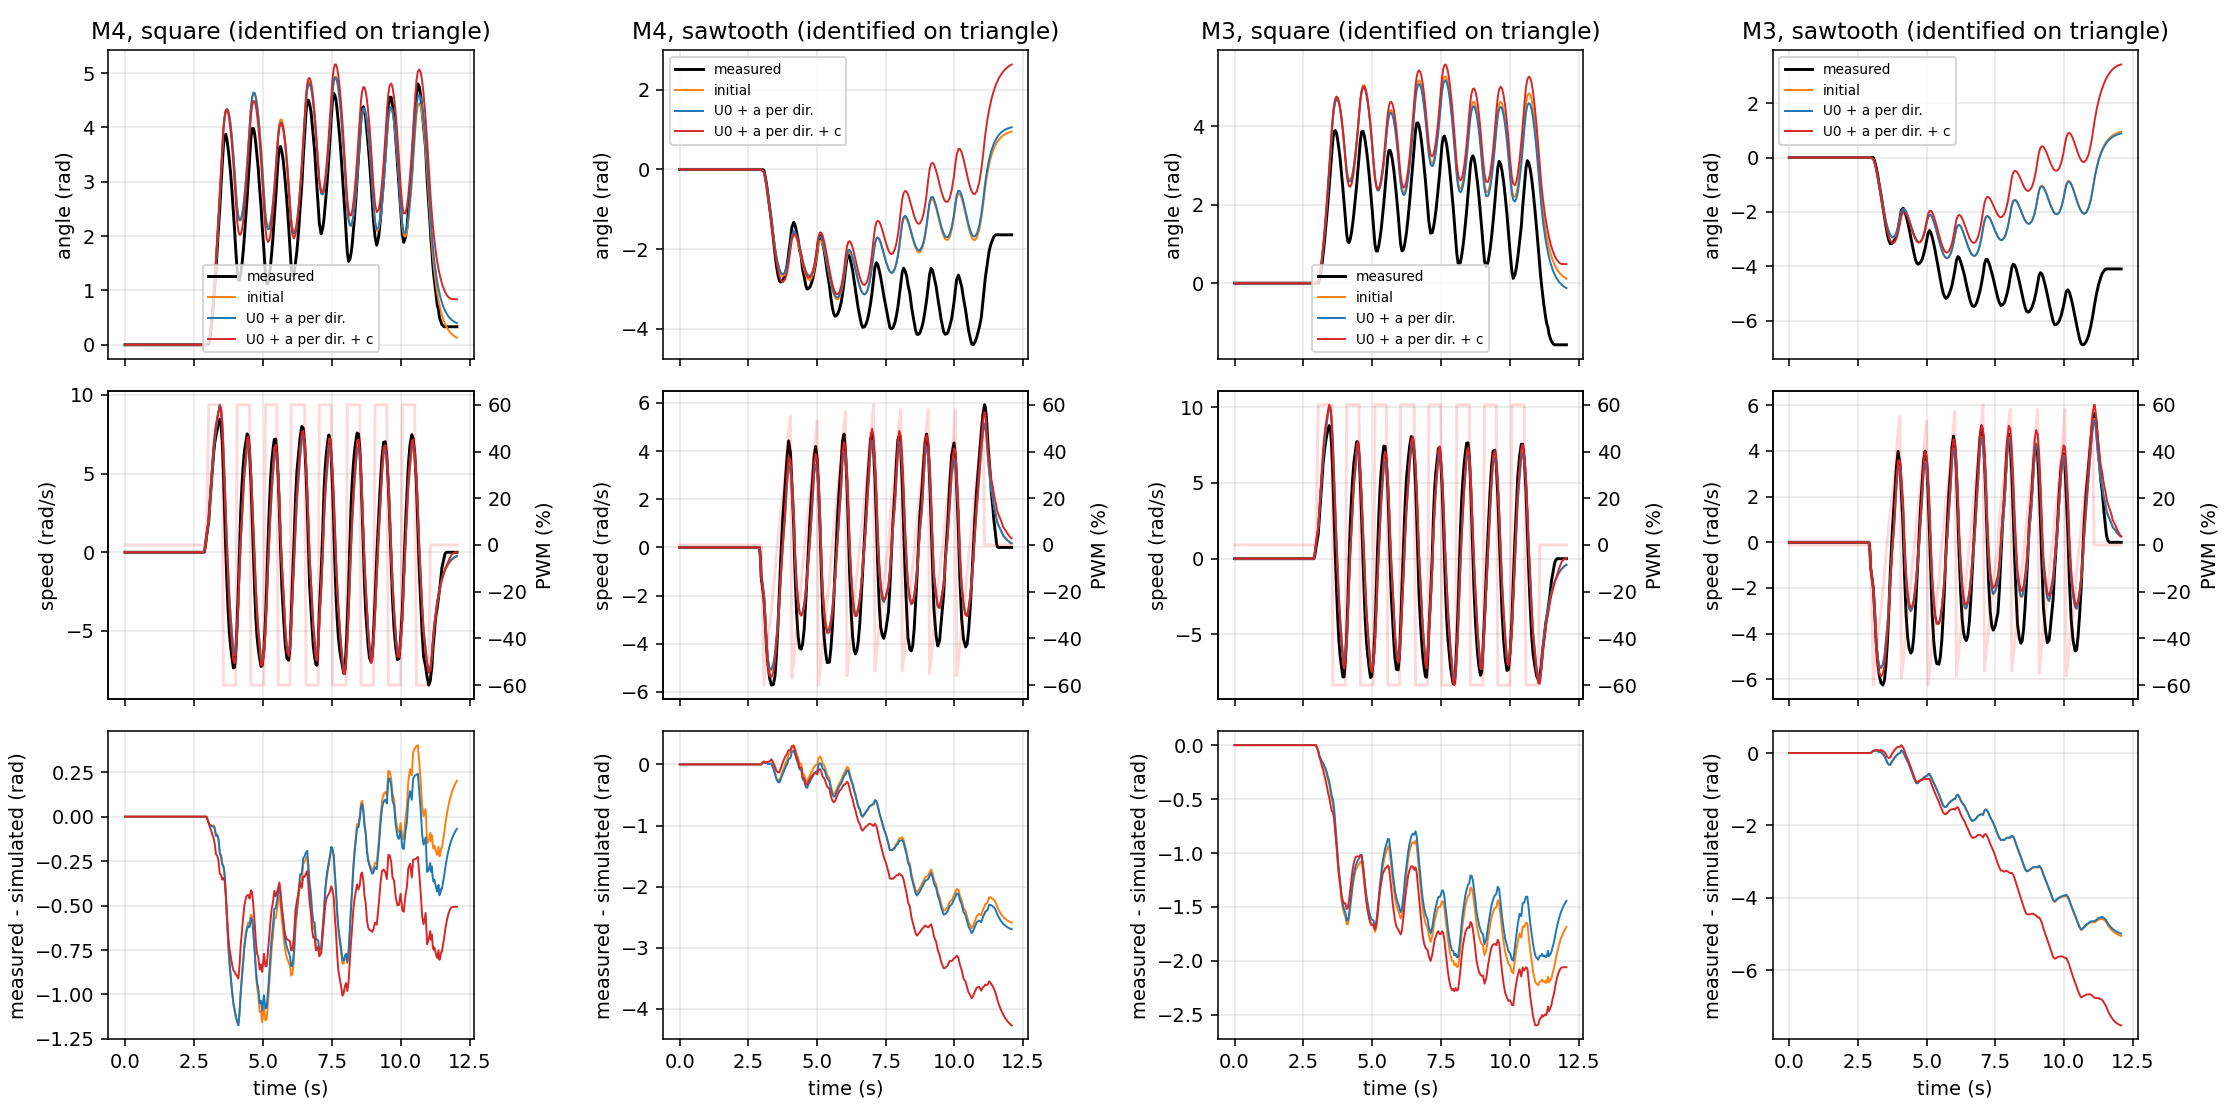

In [251]:
cols = {'initial': 'tab:orange', 'a per dir.': 'tab:green', 'U0': 'tab:purple', 'U0 + a per dir.': 'tab:blue', 'U0 + a per dir. + c': 'tab:red'}
FT = 13 # identification signal of figures and of final model (triangle)
def validation_figure(ft, versions, name):
    tests = [r for r in TRAIN if r != ft]; fig, axes = plt.subplots(3, 4, figsize=(16, 8), sharex='col')
    for c, (m, te) in enumerate([(m, te) for m in MOTORS for te in tests]):
        R = RUN[m, te]; t = R['t'] - R['t'][0]
        axes[0, c].plot(t, R['y'], 'k', label='measured'); 
        axes[1, c].plot(t, R['wm'], 'k')
        for v in versions:
            th, w = curve(FIT[m, ft, v][0], R)
            axes[0, c].plot(t, th, color=cols[v], label=v, lw=1); 
            axes[1, c].plot(t, w, color=cols[v], lw=1); 
            axes[2, c].plot(t, R['y']-th, color=cols[v], lw=1)
        g = sig(m, te); ax2 = axes[1, c].twinx(); ax2.plot(t, g.pwm, color='r', alpha=.15); ax2.set_ylabel('PWM (%)')
        axes[0, c].set(title=f'M{m}, {NAMES[te]} (identified on {NAMES[ft]})', ylabel='angle (rad)'); axes[1, c].set(ylabel='speed (rad/s)')
        axes[2, c].set(ylabel='measured - simulated (rad)', xlabel='time (s)'); axes[0, c].legend(fontsize=7)
        for a in axes[:, c]: a.grid(alpha=.3)
    show(fig, name)
validation_figure(FT, ['initial', 'U0 + a per dir.', 'U0 + a per dir. + c'], 'fig2_test_signals')

fig. 2: identified on the triangle, tested on square and sawtooth t

speeds of all versions follow amplitude and phase of both test signals and look almost the same

angles drift away from the measurement for all versions: at the end of the sawtooth, measured minus simulated is $-2.6$ rad (initial, "U0 + a per dir.") and $-4.3$ rad (with $c$) for M4, and $-5.0$ and $-7.5$ rad for M3; on the square M3 is 1.5-2.5 rad off and M4 within 1.2 rad. the line of "U0 + a per dir." lies on top of "initial" ($U\approx0$, $b_{bw}\approx0.02$). the measured angle of M3 drifts backward more than for any version: this is the wheel difference seen in the main report, which identification on the triangle does not capture.

## 5. check against the step logs (not fitted)

main report recorded steps up to 100% PWM; signals reach only 60%. late step speed of every PWM level (slope of the angle over the last quarter of each powered step, mean of the 2 repeats) is compared with the steady speed $\omega_{ss}(U)$ of each identified version; 

*no constant was fitted to step*

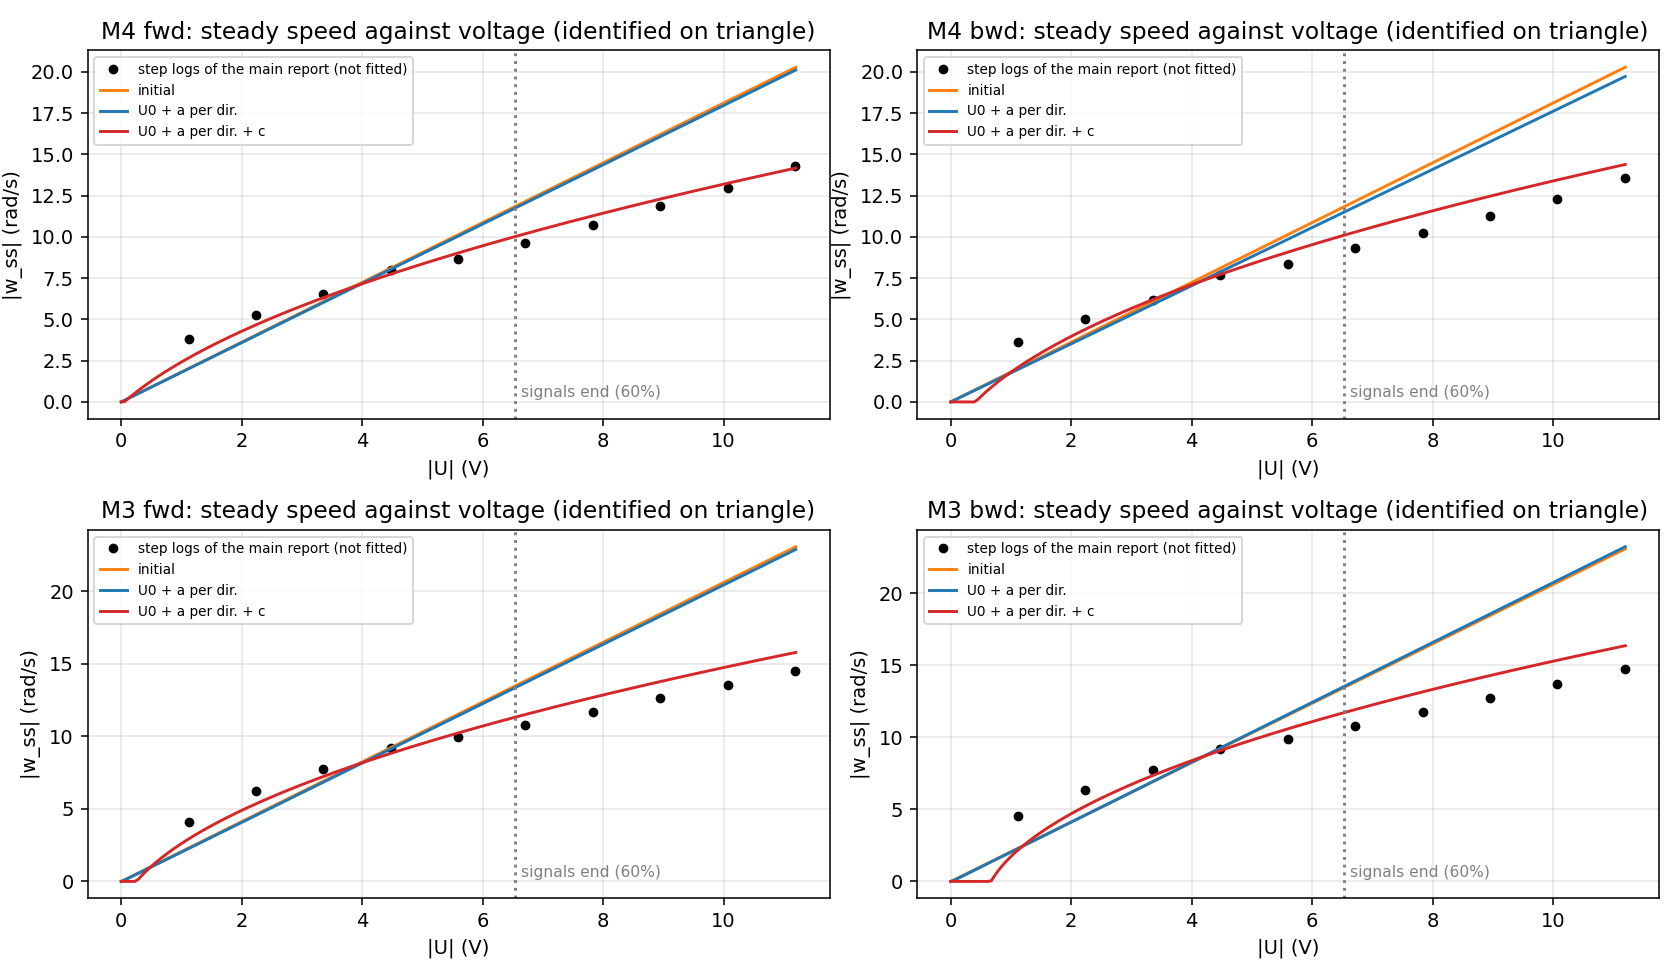

table 4: steady speed of each version against the step logs (rad/s)

version                            initial                       \
                    RMSE up to 60% (rad/s) RMSE 70-100% (rad/s)   
motor identified on                                               
M3    sawtooth                       11.30                29.46   
      square                          2.84                 0.72   
      triangle                        1.80                 6.60   
M4    sawtooth                        5.05                13.98   
      square                          1.28                 2.87   
      triangle                        1.54                 5.18   

version                         a per dir.                       \
                    RMSE up to 60% (rad/s) RMSE 70-100% (rad/s)   
motor identified on                                               
M3    sawtooth                        2.31                 4.64   
      square                          2.05                 2.25   
      triangle                        1.82                 6.72   
M4    sawtooth                        1.54                 3.84   
      square                          1.39                 1.99   
      triangle                        1.46                 4.86   

version                                 U0                       \
                    RMSE up to 60% (rad/s) RMSE 70-100% (rad/s)   
motor identified on                                               
M3    sawtooth                       12.81                32.86   
      square                          2.84                 0.71   
      triangle                        1.80                 6.60   
M4    sawtooth                        5.78                15.67   
      square                          1.59                 3.89   
      triangle                        1.67                 5.54   

version                    U0 + a per dir.                       \
                    RMSE up to 60% (rad/s) RMSE 70-100% (rad/s)   
motor identified on                                               
M3    sawtooth                        2.27                 5.75   
      square                          2.05                 2.31   
      triangle                        1.80                 6.58   
M4    sawtooth                        1.56                 3.96   
      square                          1.40                 1.96   
      triangle                        1.46                 4.86   

version                U0 + a per dir. + c                       
                    RMSE up to 60% (rad/s) RMSE 70-100% (rad/s)  
motor identified on                                              
M3    sawtooth                        1.91                 3.05  
      square                          1.97                 0.64  
      triangle                        0.99                 1.37  
M4    sawtooth                        1.35                 2.18  
      square                          1.04                 1.60  
      triangle                        0.74                 0.82

In [255]:
d = np.loadtxt(DATA/'steps_240057.txt', delimiter=','); rows = []
for motor, ca, cp, sg in [(4, 0, 2, 1), (3, 3, 4, -1)]:
    for (run, seg), ix in pd.DataFrame(dict(run=d[:, 5], ph=d[:, 6], seg=d[:, 7], i=np.arange(len(d)))).query('ph == 1').groupby(['run', 'seg']).i:
        ix = ix.to_numpy(); p = sg*d[ix[0], cp];
        if p == 0: continue
        t = d[ix, 1]/1000; y = sg*np.deg2rad(d[ix, ca]); q = max(5, len(t)//4);
        rows.append(dict(motor=motor, pwm=p, U=p*d[ix, 9].mean()/100, w=np.polyfit(t[-q:], y[-q:], 1)[0]))
stp = pd.DataFrame(rows).groupby(['motor', 'pwm']).agg(U=('U', 'mean'), w=('w', 'mean')).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r_, m in enumerate(MOTORS):
    s = stp[stp.motor == m]
    for di, (dn, sgn) in enumerate((('fwd', 1), ('bwd', -1))):
        ax = axes[r_, di]; g = s[np.sign(s.pwm) == sgn]
        ax.plot(np.abs(g.U), np.abs(g.w), 'ko', markersize=4, label='step logs of the main report (not fitted)')
        U = np.linspace(0, 11.2, 200)
        for v in ('initial', 'U0 + a per dir.', 'U0 + a per dir. + c'):
            P = FIT[m, FT, v][0]; U0, a, c = P[1 + 3*di: 4 + 3*di]; ax.plot(U, wss(U, U0, a, c), color=cols[v], label=v)
        ax.axvline(.6*10.89, color='grey', ls=':'); ax.text(.6*10.89 + .1, .3, 'signals end (60%)', fontsize=8, color='grey')
        ax.set(title=f'M{m} {dn}: steady speed against voltage (identified on {NAMES[FT]})', 
               xlabel='|U| (V)', 
               ylabel='|w_ss| (rad/s)');
        ax.grid(alpha=.3); ax.legend(fontsize=7);

show(fig, 'fig3_static_curve')
chk = []
for m in MOTORS:
    s = stp[stp.motor == m]
    for tr in TRAIN:
        for v in VERSIONS:
            P = FIT[m, tr, v][0]; err = []
            for _, rr in s.iterrows():
                di = 0 if rr.pwm > 0 else 1; 
                U0, a, c = P[1 + 3*di: 4 + 3*di]; 
                err.append(float(wss(abs(rr.U), U0, a, c)) - abs(rr.w))
            err = np.array(err); lo = np.abs(s.pwm.to_numpy()) <= 60
            chk.append({'motor': f'M{m}', 
                        'identified on': NAMES[tr], 
                        'version': v, 
                        'RMSE up to 60% (rad/s)': np.sqrt(np.mean(err[lo]**2)), 
                        'RMSE 70-100% (rad/s)': np.sqrt(np.mean(err[~lo]**2))
                       })
display(Markdown('table 4: steady speed of each version against the step logs (rad/s)'))
display(pd.DataFrame(chk).set_index(['motor', 'identified on', 'version']).unstack('version').round(2).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[[(v, k) for v in VERSIONS for k in ('RMSE up to 60% (rad/s)', 'RMSE 70-100% (rad/s)')]])

fig. 3 and table 4
- "initial" and "U0 + a per dir." give the same straight line: 20-23 rad/s at 11.2 V against 14-15 rad/s measured
- with $c$ the curve is followed: the RMSE at 70-100% is 0.8 (M4) and 1.4 rad/s (M3) against 4.9-5.5 and 6.6-6.7 for the versions without $c$, i.e. 5-7 times smaller; up to 60% it is 0.7 / 1.0 against 1.5 / 1.8. in table 4 the version with $c$ has the lowest error at 70-100% for every identification signal and both wheels (0.6-3.1 rad/s);
- with the sawtooth as identification signal the versions with one $a$ miss by 14-33 rad/s. at the lowest voltage (1.1 V, 10% PWM) the wheel runs at 3.6-4.5 rad/s, above every version (about 2-3 rad/s): the curve is steepest near zero, the opposite of a dead zone.

## 6. final model

In [259]:
FINAL = 'U0 + a per dir.' # "+ c" is shown next to it
lines = []
for m in MOTORS:
    kw = to_motor_args(FIT[m, FT, FINAL][0])
    lines.append(f'**M{m}** ({MOTORS[m]}), identified on the {NAMES[FT]}: `T_m={kw["T_m"]:.3f}, k_e={kw["k_e"]:.3f}, U_fw={kw["U_fw"]:.3f}, U_bw={kw["U_bw"]:.3f}, b_fw=0, b_bw={kw["b_bw"]:.3f}`')
display(Markdown('\n\n'.join(lines)))
lines = []
for m in MOTORS:
    tau, U0f, af, cf, U0b, ab, cb = FIT[m, FT, 'U0 + a per dir. + c'][0]
    lines.append(f'**M{m}**, with $c$: $\\tau={tau:.3f}$, forward $U_0={U0f:.3f}$, $a={af:.3f}$; backward $U_0={U0b:.3f}$, $a={ab:.3f}$; $c={cf:.3f}$ (same in both directions)')
display(Markdown('\n\n'.join(lines)))

**M4** (Left M4/E4), identified on the triangle: `T_m=0.280, k_e=0.557, U_fw=0.000, U_bw=0.000, b_fw=0, b_bw=0.020`

**M3** (Right M3/E3), identified on the triangle: `T_m=0.320, k_e=0.489, U_fw=0.012, U_bw=0.020, b_fw=0, b_bw=-0.015`

**M4**, with $c$: $\tau=0.149$, forward $U_0=0.051$, $a=0.311$; backward $U_0=0.409$, $a=0.267$; $c=0.034$ (same in both directions)

**M3**, with $c$: $\tau=0.149$, forward $U_0=0.253$, $a=0.205$; backward $U_0=0.668$, $a=0.138$; $c=0.031$ (same in both directions)

identification signal: `triangle` (slowest signal, the only one that stays at mid speeds; no signal wins on all scores, table 3 shows the others)

"U0 + a per dir." (section 1.2, constants above) is practically the initial model ($U\approx0$, $b_{bw}\approx2$%): like the initial model, it overestimates the speed above 60% PWM by 5-7 rad/s (fig. 3); 

adding $c$ gives $\tau\dot\omega=U-\operatorname{sgn}(\omega)\,(U_0^{dir}+a^{dir}|\omega|+c\,\omega^2)$ with the constants printed above; it is the only version that follows the step logs up to 100% PWM and gains 1-2 points of speed fit, and $T_m(\omega_0)=\tau/(a+2c\omega_0)$ falls with speed as the main report found.

what it costs: the angle prediction on the sawtooth is worse than for the other versions (fig. 2), and the fwd/bwd constants ($U_0$, $a$) move with the identification signal

## 7. assumptions and limits
| assumption | holds? | evidence |
|---|---|---|
| inductance negligible | assumed | sample interval 46-58 ms, a millisecond time constant cannot be seen |
| no dry friction / dead zone | **not supported as a dead zone** | $U_{fw},U_{bw}$ at most 0.06 V (0.6% PWM) in every fit of "U0 + a per dir."; "U0" alone gives no gain; a very narrow dead zone cannot be resolved by a 4 s triangle (it crosses zero at 60% PWM per second) |
| drag linear in speed | **no** | step logs: error at 70-100% PWM 5-7 times smaller with $c$; $T_m$ falls with speed |
| voltage proportional to PWM | assumed | set A (different bat. voltage) is predicted like set B |
| forward = backward | **approximately** | small (main report 4.9% / 1.6%; $b_{bw}$ from the triangle 0.02 / $-0.015$) but it changes with the identification signal ($-0.2$ to $-0.3$ from the sawtooth) |

**other limits**
- one 8s signal identifies each fit; constants shift between identification signals (section 4.1), so the numbers of section 6 are one possible result; all signals reach $\pm60$% only;
- 4s triangle is the slowest signal, so dead zone below its resolution cannot be excluded; as said earlier in report test on low frequency chirp would let us test possible deadzone range;
- only PWM and angle were recorded, so $R,K,J,B_1,B_2,T_c$ are combined into $\tau,a,U_0,c$; $b_{fw}=0$ is a fixed convention (sect. 1.2), not measurement